# Predicting Loan Default Risk Using Apache Spark and Machine Learning

This notebook is the single source of truth for the project. It loads and validates the supplied 5,000-record dataset, performs exploratory analysis, trains and compares PySpark models, selects a model and threshold using validation data, evaluates once on the untouched test set, and writes every file consumed by the Streamlit dashboard.

## Objectives
- Process borrower and loan data with PySpark.
- Compare Logistic Regression and Random Forest with weighted and unweighted training.
- Use a leakage-safe stratified 64:16:20 train/validation/test split.
- Tune the decision threshold on validation data only.
- Save reproducible metrics, predictions, model artifacts, and visualizations.

The sample is a sequential subset and the risk bands are illustrative ranking categories, not a lending policy.


## 1. Imports and SparkSession initialization

In [1]:
import builtins
import json
import os
import sys
from pathlib import Path

# Use the caller's Java installation; fall back to the common Homebrew Java 17 path on macOS.
_mac_java17 = "/opt/homebrew/opt/openjdk@17/libexec/openjdk.jdk/Contents/Home"
if "JAVA_HOME" not in os.environ and Path(_mac_java17).exists():
    os.environ["JAVA_HOME"] = _mac_java17
os.environ["PYSPARK_PYTHON"] = sys.executable
os.environ["PYSPARK_DRIVER_PYTHON"] = sys.executable
os.environ.pop("SPARK_HOME", None)
os.environ.pop("SPARK_CONF_DIR", None)
os.environ.pop("PYSPARK_SUBMIT_ARGS", None)

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from pyspark.ml import Pipeline
from pyspark.ml.classification import LogisticRegression, RandomForestClassifier
from pyspark.ml.evaluation import BinaryClassificationEvaluator
from pyspark.ml.feature import OneHotEncoder, StringIndexer, VectorAssembler
from pyspark.ml.functions import vector_to_array
from pyspark.sql import DataFrame, SparkSession
from pyspark.sql.functions import avg, col, count, desc, lit, rand, row_number, when
from pyspark.sql.types import NumericType, StringType
from pyspark.sql.window import Window

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "Notebooks" else Path.cwd()
DATA_PATH = PROJECT_ROOT / "data" / "raw" / "Loan_default .csv"
OUTPUTS = PROJECT_ROOT / "outputs"
MODEL_DIR = OUTPUTS / "model"
TABLES_DIR = OUTPUTS / "tables"
GRAPHS_DIR = OUTPUTS / "graphs"
for directory in (MODEL_DIR, TABLES_DIR, GRAPHS_DIR):
    directory.mkdir(parents=True, exist_ok=True)

spark = (
    SparkSession.builder.appName("LoanDefaultRiskPrediction").master("local[2]")
    .config("spark.sql.shuffle.partitions", "4")
    .config("spark.ui.enabled", "false").getOrCreate()
)
spark.sparkContext.setLogLevel("ERROR")
print("Spark version:", spark.version)


26/11/02 19:32:20 WARN Utils: Your hostname, Anis-Macbook-air.local resolves to a loopback address: 127.0.0.1; using 10.209.42.177 instead (on interface en0)
26/11/02 19:32:20 WARN Utils: Set SPARK_LOCAL_IP if you need to bind to another address
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).


26/11/02 19:32:20 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


Spark version: 3.5.6


## 2. Dataset loading and inspection

In [2]:
if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Dataset not found: {DATA_PATH}. Download 'Loan_default .csv', keep the header and first "
        "5,000 records, and place it in data/raw/."
    )

df = (spark.read.option("header", True).option("inferSchema", True).csv(str(DATA_PATH)))
print("Rows:", df.count(), "Columns:", len(df.columns))
df.printSchema()
df.show(5, truncate=False)


Rows: 5000 Columns: 18
root
 |-- LoanID: string (nullable = true)
 |-- Age: integer (nullable = true)
 |-- Income: integer (nullable = true)
 |-- LoanAmount: integer (nullable = true)
 |-- CreditScore: integer (nullable = true)
 |-- MonthsEmployed: integer (nullable = true)
 |-- NumCreditLines: integer (nullable = true)
 |-- InterestRate: double (nullable = true)
 |-- LoanTerm: integer (nullable = true)
 |-- DTIRatio: double (nullable = true)
 |-- Education: string (nullable = true)
 |-- EmploymentType: string (nullable = true)
 |-- MaritalStatus: string (nullable = true)
 |-- HasMortgage: string (nullable = true)
 |-- HasDependents: string (nullable = true)
 |-- LoanPurpose: string (nullable = true)
 |-- HasCoSigner: string (nullable = true)
 |-- Default: integer (nullable = true)

+----------+---+------+----------+-----------+--------------+--------------+------------+--------+--------+-----------+--------------+-------------+-----------+-------------+-----------+-----------+-------+

## 3. Data validation and cleaning

Validation is intentionally strict: invalid schemas, nulls, duplicate rows/IDs, and non-binary labels stop execution rather than silently changing the dataset.

In [3]:
NUMERIC_FEATURES = [
    "Age", "Income", "LoanAmount", "CreditScore", "MonthsEmployed",
    "NumCreditLines", "InterestRate", "LoanTerm", "DTIRatio",
]
CATEGORICAL_FEATURES = [
    "Education", "EmploymentType", "MaritalStatus", "HasMortgage",
    "HasDependents", "LoanPurpose", "HasCoSigner",
]
REQUIRED_COLUMNS = ["LoanID", *NUMERIC_FEATURES, *CATEGORICAL_FEATURES, "Default"]
LOW_RISK_UPPER = 0.30
MEDIUM_RISK_UPPER = 0.60

def validate_input_dataframe(frame: DataFrame) -> None:
    missing_columns = [name for name in REQUIRED_COLUMNS if name not in frame.columns]
    if missing_columns:
        raise ValueError(f"Dataset is missing required columns: {', '.join(missing_columns)}")
    invalid_types = []
    for name in NUMERIC_FEATURES + ["Default"]:
        if not isinstance(frame.schema[name].dataType, NumericType):
            invalid_types.append(f"{name} ({frame.schema[name].dataType.simpleString()})")
    for name in ["LoanID", *CATEGORICAL_FEATURES]:
        if not isinstance(frame.schema[name].dataType, StringType):
            invalid_types.append(f"{name} ({frame.schema[name].dataType.simpleString()})")
    if invalid_types:
        raise ValueError("Dataset has invalid column types: " + ", ".join(invalid_types))
    missing_counts = frame.select([col(name).isNull().cast("long").alias(name) for name in REQUIRED_COLUMNS]).groupBy().sum().first().asDict()
    missing = {name: int(missing_counts.get(f"sum({name})") or 0) for name in REQUIRED_COLUMNS if int(missing_counts.get(f"sum({name})") or 0) > 0}
    if missing:
        raise ValueError("Dataset contains missing values: " + ", ".join(f"{k}={v}" for k, v in missing.items()))
    invalid_labels = [row["Default"] for row in frame.select("Default").distinct().collect() if row["Default"] not in (0, 1, 0.0, 1.0)]
    if invalid_labels:
        raise ValueError(f"Default must contain only 0 and 1; found {invalid_labels}")
    duplicate_rows = frame.count() - frame.dropDuplicates().count()
    if duplicate_rows:
        raise ValueError(f"Dataset contains {duplicate_rows} duplicate row(s)")
    duplicate_ids = frame.count() - frame.select("LoanID").distinct().count()
    if duplicate_ids:
        raise ValueError(f"Dataset contains {duplicate_ids} duplicate LoanID row(s)")

validate_input_dataframe(df)
print("Validation passed.")
print("Duplicate rows:", df.count() - df.dropDuplicates().count())
print("Unique Loan IDs:", df.select("LoanID").distinct().count())
df.groupBy("Default").count().orderBy("Default").show()


Validation passed.
Duplicate rows: 0


Unique Loan IDs: 5000
+-------+-----+
|Default|count|
+-------+-----+
|      0| 4414|
|      1|  586|
+-------+-----+



## 4. Exploratory data analysis

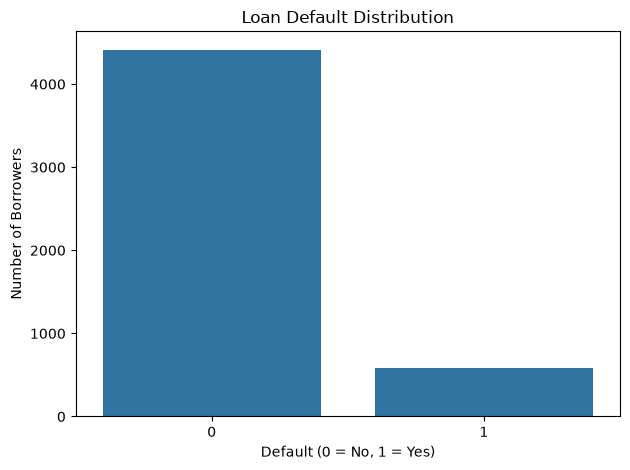


Default rate by EmploymentType
+--------------+-----------+------------------+
|EmploymentType|Total_Loans|      Default_Rate|
+--------------+-----------+------------------+
|    Unemployed|       1258|13.593004769475359|
|     Part-time|       1234|12.317666126418152|
| Self-employed|       1292|10.913312693498451|
|     Full-time|       1216|10.032894736842106|
+--------------+-----------+------------------+


Default rate by Education


+-----------+-----------+------------------+
|  Education|Total_Loans|      Default_Rate|
+-----------+-----------+------------------+
| Bachelor's|       1275|13.176470588235295|
|High School|       1264|12.104430379746836|
|        PhD|       1244|11.173633440514468|
|   Master's|       1217|10.353327855382087|
+-----------+-----------+------------------+


Default rate by MaritalStatus
+-------------+-----------+------------------+
|MaritalStatus|Total_Loans|      Default_Rate|
+-------------+-----------+------------------+
|     Divorced|       1647|13.296903460837886|
|       Single|       1687| 11.14404267931239|
|      Married|       1666|10.744297719087635|
+-------------+-----------+------------------+


Default rate by LoanPurpose
+-----------+-----------+------------------+
|LoanPurpose|Total_Loans|      Default_Rate|
+-----------+-----------+------------------+
|      Other|       1006|13.618290258449303|
|   Business|        967|12.306101344364013|
|       Home|       1018

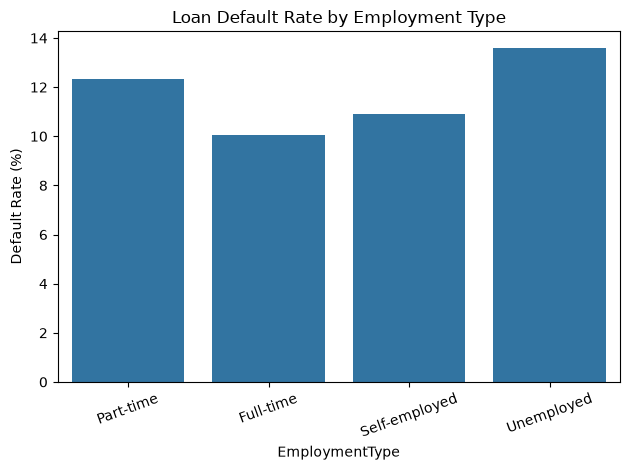

+-------+-----------------+-----------------+------------------+-----------------+------------------+------------------+------------------+-----------------+------------------+
|Default|Age              |Income           |LoanAmount        |CreditScore      |MonthsEmployed    |NumCreditLines    |InterestRate      |LoanTerm         |DTIRatio          |
+-------+-----------------+-----------------+------------------+-----------------+------------------+------------------+------------------+-----------------+------------------+
|0      |44.63389216130494|84001.36520163117|126775.33665609425|578.7451291345718|60.084050747621205|2.4857272315360217|13.115240144993164|36.24195740824649|0.5014997734481189|
|1      |35.68088737201365|73063.61774744028|142540.25938566553|552.2303754266212|50.329351535836174|2.5665529010238908|15.940477815699644|36.40955631399317|0.5059044368600681|
+-------+-----------------+-----------------+------------------+-----------------+------------------+--------------

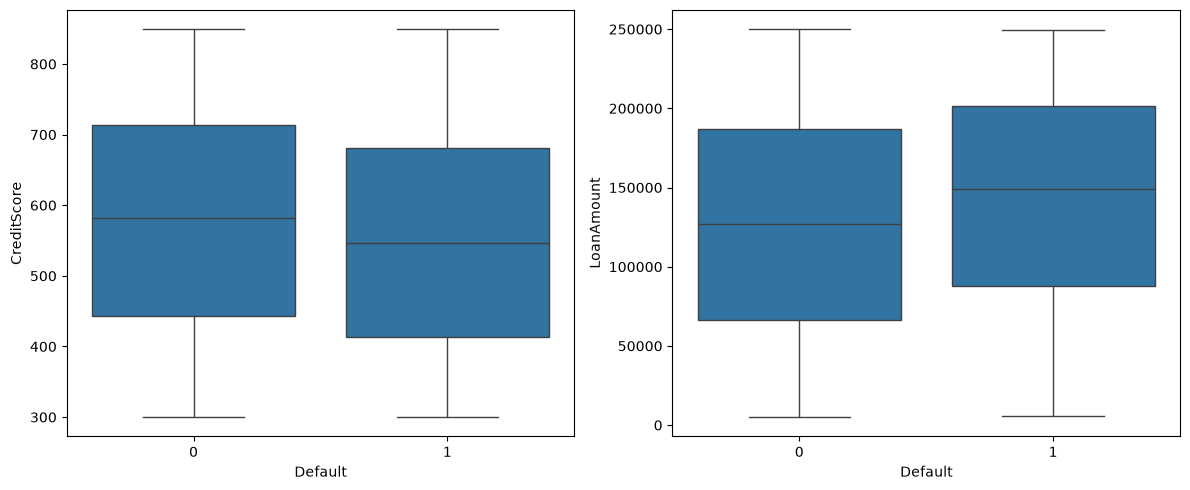

          Feature  Correlation with Default
6    InterestRate                  0.137199
2      LoanAmount                  0.072182
5  NumCreditLines                  0.023143
8        DTIRatio                  0.006184
7        LoanTerm                  0.003164
3     CreditScore                 -0.053935
1          Income                 -0.089817
4  MonthsEmployed                 -0.091036
0             Age                 -0.193048


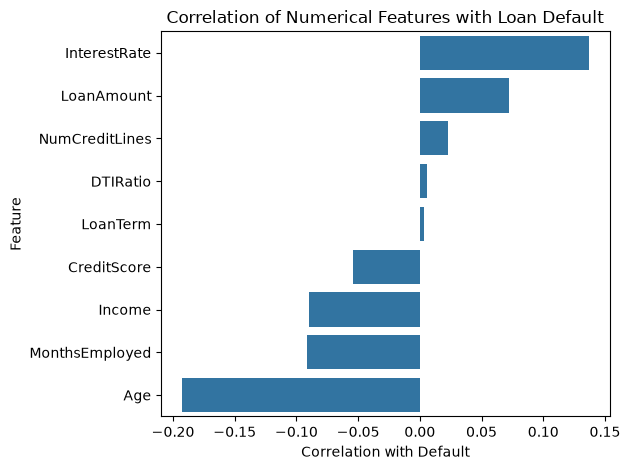

In [4]:
target_pd = df.groupBy("Default").count().toPandas()
sns.barplot(data=target_pd, x="Default", y="count")
plt.title("Loan Default Distribution")
plt.xlabel("Default (0 = No, 1 = Yes)")
plt.ylabel("Number of Borrowers")
plt.tight_layout()
plt.savefig(GRAPHS_DIR / "default_distribution.png", dpi=200)
plt.show()

for feature in ["EmploymentType", "Education", "MaritalStatus", "LoanPurpose"]:
    print(f"\nDefault rate by {feature}")
    (df.groupBy(feature).agg(count("*").alias("Total_Loans"), (avg("Default") * 100).alias("Default_Rate"))
       .orderBy(desc("Default_Rate")).show())

employment_pd = df.groupBy("EmploymentType").agg((avg("Default") * 100).alias("Default_Rate")).toPandas()
sns.barplot(data=employment_pd, x="EmploymentType", y="Default_Rate")
plt.title("Loan Default Rate by Employment Type")
plt.ylabel("Default Rate (%)")
plt.xticks(rotation=20)
plt.tight_layout()
plt.savefig(GRAPHS_DIR / "default_by_employment.png", dpi=200)
plt.show()

numeric_analysis = df.groupBy("Default").agg(*[avg(c).alias(c) for c in NUMERIC_FEATURES]).orderBy("Default")
numeric_analysis.show(truncate=False)
plot_df = df.select("Default", "CreditScore", "LoanAmount").toPandas()
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sns.boxplot(data=plot_df, x="Default", y="CreditScore", ax=axes[0])
sns.boxplot(data=plot_df, x="Default", y="LoanAmount", ax=axes[1])
plt.tight_layout()
plt.savefig(GRAPHS_DIR / "numerical_feature_analysis.png", dpi=200)
plt.show()

correlation_df = pd.DataFrame([(feature, df.stat.corr(feature, "Default")) for feature in NUMERIC_FEATURES], columns=["Feature", "Correlation with Default"]).sort_values("Correlation with Default", ascending=False)
print(correlation_df)
sns.barplot(data=correlation_df, x="Correlation with Default", y="Feature")
plt.title("Correlation of Numerical Features with Loan Default")
plt.tight_layout()
plt.savefig(GRAPHS_DIR / "feature_correlation.png", dpi=200)
plt.show()


## 5. Feature engineering and preprocessing

Categorical indexers, encoding, and assembly are fitted on training data only. The same fitted preprocessing model is then applied to validation and test data.

In [5]:
def make_preprocessing_pipeline() -> Pipeline:
    indexers = [StringIndexer(inputCol=name, outputCol=f"{name}_Index", handleInvalid="keep") for name in CATEGORICAL_FEATURES]
    encoder = OneHotEncoder(inputCols=[f"{name}_Index" for name in CATEGORICAL_FEATURES], outputCols=[f"{name}_Encoded" for name in CATEGORICAL_FEATURES], handleInvalid="keep")
    assembler = VectorAssembler(inputCols=NUMERIC_FEATURES + [f"{name}_Encoded" for name in CATEGORICAL_FEATURES], outputCol="features", handleInvalid="keep")
    return Pipeline(stages=indexers + [encoder, assembler])

def stratified_split(frame: DataFrame, seed: int = 42):
    ranked = frame.withColumn("_split_rank", row_number().over(Window.partitionBy("Default").orderBy(rand(seed))))
    counts = {row["Default"]: row["count"] for row in frame.groupBy("Default").count().collect()}
    train_cutoffs = {label: int(count * 0.64) for label, count in counts.items()}
    validation_cutoffs = {label: int(count * 0.80) for label, count in counts.items()}
    train_condition = lit(False)
    validation_condition = lit(False)
    for label in counts:
        train_condition = train_condition | ((col("Default") == label) & (col("_split_rank") <= train_cutoffs[label]))
        validation_condition = validation_condition | ((col("Default") == label) & (col("_split_rank") > train_cutoffs[label]) & (col("_split_rank") <= validation_cutoffs[label]))
    return (ranked.filter(train_condition).drop("_split_rank"), ranked.filter(validation_condition).drop("_split_rank"), ranked.filter(~train_condition & ~validation_condition).drop("_split_rank"))

train, validation, test = stratified_split(df)
print("Split sizes:", train.count(), validation.count(), test.count())
assert train.count() + validation.count() + test.count() == df.count()
assert train.select("LoanID").intersect(validation.select("LoanID")).count() == 0
assert train.select("LoanID").intersect(test.select("LoanID")).count() == 0
assert validation.select("LoanID").intersect(test.select("LoanID")).count() == 0
preprocessing_model = make_preprocessing_pipeline().fit(train)
prepared_train = preprocessing_model.transform(train).cache()
prepared_validation = preprocessing_model.transform(validation).cache()


Split sizes: 3199 800 1001


## 6. Stratified 64:16:20 split and class imbalance handling

In [6]:
def add_class_weights(frame: DataFrame) -> DataFrame:
    counts = {row["Default"]: row["count"] for row in frame.groupBy("Default").count().collect()}
    total = builtins.sum(counts.values())
    weights = {label: total / (len(counts) * count) for label, count in counts.items()}
    return frame.withColumn("classWeight", when(col("Default") == 1, lit(weights[1])).otherwise(lit(weights[0])))

weighted_train = add_class_weights(train)
weighted_prepared_train = preprocessing_model.transform(weighted_train).cache()
for name, frame in [("train", train), ("validation", validation), ("test", test)]:
    print(name, frame.groupBy("Default").count().orderBy("Default").collect())


train [Row(Default=0, count=2824), Row(Default=1, count=375)]
validation [Row(Default=0, count=707), Row(Default=1, count=93)]


test [Row(Default=0, count=883), Row(Default=1, count=118)]


## 7. Logistic Regression and Random Forest training

In [7]:
def build_classifier(model_name: str, weighted: bool):
    if model_name == "Logistic Regression":
        classifier = LogisticRegression(featuresCol="features", labelCol="Default", maxIter=100, regParam=0.0)
    else:
        classifier = RandomForestClassifier(featuresCol="features", labelCol="Default", numTrees=150, maxDepth=8, seed=42)
    if weighted:
        classifier.setWeightCol("classWeight")
    return classifier

def with_threshold(predictions: DataFrame, threshold: float) -> DataFrame:
    return predictions.withColumn("prediction", when(vector_to_array("probability")[1] >= lit(threshold), lit(1.0)).otherwise(lit(0.0)))

def evaluate(predictions: DataFrame, model_name: str, threshold: float) -> dict:
    counts = predictions.select(((col("Default") == 1) & (col("prediction") == 1)).cast("int").alias("tp"), ((col("Default") == 0) & (col("prediction") == 0)).cast("int").alias("tn"), ((col("Default") == 0) & (col("prediction") == 1)).cast("int").alias("fp"), ((col("Default") == 1) & (col("prediction") == 0)).cast("int").alias("fn")).groupBy().sum().first()
    tp, tn, fp, fn = [int(counts[f"sum({key})"] or 0) for key in ("tp", "tn", "fp", "fn")]
    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0.0
    total = tp + tn + fp + fn
    auc = BinaryClassificationEvaluator(labelCol="Default", rawPredictionCol="rawPrediction", metricName="areaUnderROC").evaluate(predictions)
    return {"Model": model_name, "Threshold": threshold, "Accuracy": (tp + tn) / total, "Precision": precision, "Recall": recall, "F1 Score": f1, "ROC-AUC": auc, "TN": tn, "FP": fp, "FN": fn, "TP": tp}

def select_threshold(predictions: DataFrame, model_name: str):
    candidates = [round(x / 100, 2) for x in range(10, 81, 5)]
    results = [evaluate(with_threshold(predictions, threshold), model_name, threshold) for threshold in candidates]
    best = max(results, key=lambda row: (row["F1 Score"], row["Recall"], row["Precision"]))
    return best["Threshold"], best

candidate_results = []
for model_name in ("Logistic Regression", "Random Forest"):
    for weighted, source in ((False, prepared_train), (True, weighted_prepared_train)):
        label = f"{model_name} ({'weighted' if weighted else 'unweighted'})"
        model = build_classifier(model_name, weighted).fit(source)
        threshold, result = select_threshold(model.transform(prepared_validation), label)
        candidate_results.append(result)
        print(label, "best threshold:", threshold)


Logistic Regression (unweighted) best threshold: 0.2


Logistic Regression (weighted) best threshold: 0.65


Random Forest (unweighted) best threshold: 0.15


Random Forest (weighted) best threshold: 0.35


## 8. Model comparison and validation-based threshold tuning

,Model,Threshold,Accuracy,Precision,Recall,F1 Score,ROC-AUC,TN,FP,FN,TP
1,Logistic Regression (weighted),0.65,0.81250,0.306122,0.483871,0.375000,0.754513,605,102,48,45
0,Logistic Regression (unweighted),0.20,0.82250,0.312977,0.440860,0.366071,0.757509,617,90,52,41
2,Random Forest (unweighted),0.15,0.76625,0.265000,0.569892,0.361775,0.742057,560,147,40,53
3,Random Forest (weighted),0.35,0.70125,0.233577,0.688172,0.348774,0.745312,497,210,29,64


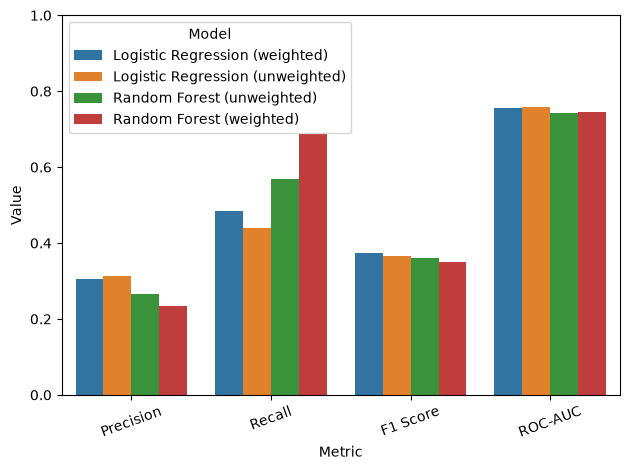

In [8]:
validation_results = pd.DataFrame(candidate_results).sort_values(["F1 Score", "Recall", "Precision", "ROC-AUC"], ascending=False)
validation_results.to_csv(TABLES_DIR / "validation_model_comparison.csv", index=False)
display(validation_results)
chart = validation_results[["Model", "Precision", "Recall", "F1 Score", "ROC-AUC"]].melt(id_vars="Model", var_name="Metric", value_name="Value")
sns.barplot(data=chart, x="Metric", y="Value", hue="Model")
plt.ylim(0, 1)
plt.xticks(rotation=20)
plt.tight_layout()
plt.savefig(GRAPHS_DIR / "model_comparison.png", dpi=200)
plt.show()


## 9. Final model selection and refitting

The top validation F1 model and threshold are selected. The selected preprocessing and classifier are refit on training plus validation rows only; the test set remains untouched until the next section.

In [9]:
selected = validation_results.iloc[0].to_dict()
selected_label = selected["Model"]
model_name = selected_label.split(" (")[0]
weighted = "weighted" in selected_label
full_train = train.unionByName(validation)
full_source = add_class_weights(full_train) if weighted else full_train
final_pipeline = Pipeline(stages=make_preprocessing_pipeline().getStages() + [build_classifier(model_name, weighted)])
final_model = final_pipeline.fit(full_source)
print("Selected model:", selected_label)
print("Selected threshold:", selected["Threshold"])
print("Rows used to refit:", full_train.count())


Selected model: Logistic Regression (weighted)
Selected threshold: 0.65
Rows used to refit: 3999


## 10. Evaluation on the untouched test set

In [10]:
final_predictions = with_threshold(final_model.transform(test), float(selected["Threshold"]))
test_result = evaluate(final_predictions, selected_label, float(selected["Threshold"]))
test_result.update({"Training rows": full_train.count(), "Validation rows": validation.count(), "Test rows": test.count(), "Selected model": selected_label})
with (TABLES_DIR / "final_test_metrics.json").open("w", encoding="utf-8") as file:
    json.dump(test_result, file, indent=2)
pd.DataFrame([test_result]).to_csv(TABLES_DIR / "final_test_metrics.csv", index=False)
print(json.dumps(test_result, indent=2))


{
  "Model": "Logistic Regression (weighted)",
  "Threshold": 0.65,
  "Accuracy": 0.8181818181818182,
  "Precision": 0.3072289156626506,
  "Recall": 0.4322033898305085,
  "F1 Score": 0.35915492957746475,
  "ROC-AUC": 0.7632781158224105,
  "TN": 768,
  "FP": 115,
  "FN": 67,
  "TP": 51,
  "Training rows": 3999,
  "Validation rows": 800,
  "Test rows": 1001,
  "Selected model": "Logistic Regression (weighted)"
}


## 11. Confusion matrix and performance visualizations

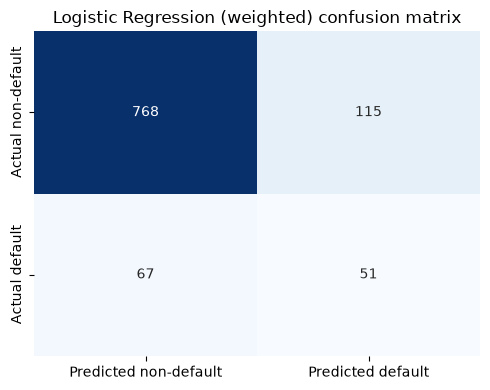

In [11]:
matrix = [[test_result["TN"], test_result["FP"]], [test_result["FN"], test_result["TP"]]]
plt.figure(figsize=(5, 4))
sns.heatmap(matrix, annot=True, fmt="d", cmap="Blues", cbar=False, xticklabels=["Predicted non-default", "Predicted default"], yticklabels=["Actual non-default", "Actual default"])
plt.title(f"{selected_label} confusion matrix")
plt.tight_layout()
plt.savefig(GRAPHS_DIR / "final_confusion_matrix.png", dpi=200)
plt.show()


## 12. Prediction generation

In [12]:
predictions = final_predictions.select("LoanID", "Default", "probability", "prediction").withColumn("default_probability", vector_to_array("probability")[1].cast("double")).drop("probability")
predictions = predictions.withColumn("risk_category", when(col("default_probability") < LOW_RISK_UPPER, "Low").when(col("default_probability") < MEDIUM_RISK_UPPER, "Medium").otherwise("High"))
predictions_pd = predictions.toPandas()
predictions_pd.to_csv(TABLES_DIR / "borrower_predictions.csv", index=False)
predictions_pd.head()


,LoanID,Default,prediction,default_probability,risk_category
0,G6D9SKV2VX,0,0.0,0.237381,Low
1,IXGSMX36YI,0,0.0,0.378399,Medium
2,7XMPSQ4821,0,0.0,0.176197,Low
3,ZZPJYWSY17,0,0.0,0.358468,Medium
4,LC9WVW2SDL,0,1.0,0.772250,High


## 13. Saving outputs for the Streamlit dashboard

In [13]:
final_model.write().overwrite().save(str(MODEL_DIR / "loan_default_pipeline"))
required_outputs = [TABLES_DIR / name for name in ("final_test_metrics.json", "final_test_metrics.csv", "borrower_predictions.csv", "validation_model_comparison.csv")]
required_outputs += [MODEL_DIR / "loan_default_pipeline"]
required_outputs += [GRAPHS_DIR / name for name in ("default_distribution.png", "default_by_employment.png", "numerical_feature_analysis.png", "feature_correlation.png", "model_comparison.png", "final_confusion_matrix.png")]
missing_outputs = [str(output) for output in required_outputs if not output.exists()]
if missing_outputs:
    raise FileNotFoundError("Expected outputs were not generated: " + ", ".join(missing_outputs))
print("All dashboard and model outputs generated under:", OUTPUTS)


All dashboard and model outputs generated under: /Users/ani/Desktop/ClusterComputing_CA2/outputs


## 14. Final observations and limitations

The dashboard labels these predictions as the held-out test set. Metrics describe this sequential 5,000-row sample and may vary with Spark or Java versions. The selected score threshold optimizes validation F1, while the test set is used only for final evaluation. Class-weighted scores are ranking scores rather than calibrated probabilities, and the Low/Medium/High bands are illustrative. Demographic features are present, so the model requires fairness and regulatory review before any real-world use.

Run the notebook from beginning to end before launching the dashboard:

```bash
source .venv/bin/activate
python -m streamlit run app.py
```


In [14]:
spark.stop()
print("Notebook execution complete.")


Notebook execution complete.
